# Part 1 — Foundations

dbt's basic features are covered extensively in tutorials, so this 
part moves quickly. The goal is a working pipeline for parts 2 to 5 to break.

**What you'll see**

- a folder of SQL files become a dependency-sequenced build
- the four-layer shape almost every dbt project uses and the specific job each
  layer does
- one CLI command, `dbt build`, that runs the whole project in the right order

Everything runs against a live SQL Server 2025 container.

> **Naming note.** *dbt Core* is the open-source engine; this runs Core 1.12
> with the `dbt-sqlserver` 1.10 adapter maintained by the community dbt-msft
> org. *dbt Platform* (formerly Cloud) is the hosted product. *Fusion* is
> dbt Labs' Rust engine, with no SQL Server adapter yet, so it isn't used here.

## Setup

`reset` returns the lab to its starting state: raw data reseeded, every
dbt-built schema dropped. It is the first cell of every notebook.

The imports are this repo's harness, [`src/lab`](../src/lab/): `dbt()` runs a
dbt command with the same argv you would type at the CLI, returning a real
result object instead of an exit code to scrape; `show()` prints a committed
project file; `shop` queries the live warehouse into DataFrames; `artifacts`
reads the JSON dbt records about its own runs, so cells assert against what
dbt did rather than scrape its logs.

In [1]:
!reset

... restoring raw seed data and dropping dbt schemas
✓ lab restored to its starting state


In [2]:
# Lab setup
import pandas as pd

from lab import artifacts, shop
from lab.runner import dbt, show

## The landing zone

The landing zone contains four tables in the `raw` schema. A separate extract & load pipeline lands them
hourly from the shop's operational systems. dbt's work starts from here.

The landing zone is loaded, never edited. The extract
and load process of an *ELT* pipeline ingests the source's data into the warehouse unaltered. Every
transformation after that is version-controlled code that can be re-run. Raw
stays the reproducible starting point. When a transformation is wrong you fix
the code and rebuild rather than repairing data in place.

In [3]:
counts = shop.df("""
    SELECT 'customers' AS raw_table, COUNT(*) AS row_count FROM raw.customers
    UNION ALL SELECT 'products',  COUNT(*) FROM raw.products
    UNION ALL SELECT 'orders',    COUNT(*) FROM raw.orders
    UNION ALL SELECT 'payments',  COUNT(*) FROM raw.payments
""")
counts

,raw_table,row_count
0,customers,8
1,products,6
2,orders,30
3,payments,24


In [4]:
shop.df("SELECT TOP 10 * FROM raw.orders ORDER BY order_id")

,order_id,customer_id,product_id,status,quantity,unit_price_cents,placed_at,updated_at,_loaded_at
0,1,1,1,delivered,2,18900,2026-07-01 09:14:00,2026-07-04 10:00:00,2026-07-04 10:05:00
1,2,3,2,delivered,10,3450,2026-07-01 11:02:00,2026-07-04 15:30:00,2026-07-04 16:05:00
2,3,2,3,delivered,5,1275,2026-07-02 10:20:00,2026-07-06 09:10:00,2026-07-06 10:05:00
3,4,4,5,shipped,1,44900,2026-07-03 14:45:00,2026-07-05 08:20:00,2026-07-05 09:05:00
4,5,5,4,delivered,12,2200,2026-07-03 16:01:00,2026-07-07 11:40:00,2026-07-07 12:05:00
5,6,1,6,shipped,1,32900,2026-07-05 08:55:00,2026-07-06 13:15:00,2026-07-06 14:05:00
6,7,6,1,delivered,3,18900,2026-07-06 09:40:00,2026-07-09 10:25:00,2026-07-09 11:05:00
7,8,7,2,cancelled,6,3450,2026-07-06 13:22:00,2026-07-07 09:00:00,2026-07-07 09:05:00
8,9,8,3,delivered,8,1275,2026-07-07 15:09:00,2026-07-10 14:50:00,2026-07-10 15:05:00
9,10,2,4,shipped,20,2200,2026-07-08 10:30:00,2026-07-09 16:45:00,2026-07-09 17:05:00


Note that data lands as-is from the operational system:

- Prices are integer cents, not dollars.
- `status` is overwritten in place as an order moves along.
- Every column is nullable, and there is not one key or constraint.

That last point is not sloppiness on the loader's part. A landing zone that
rejects rows is a landing zone that loses them. It simply accepts everything and
leaves the arguing to the transformation layer.

The final column, `_loaded_at`, is when the row *reached the warehouse*, which
is a different clock from `placed_at`, when the order was actually made.
Part 2 is entirely about the gap between these two clocks.

We want one number out of this: **revenue by day**. Getting there needs a unit
conversion, a join, and a rule about cancelled orders.

## The problem dbt solves

You could calculate revenue by day with a few SQL scripts. The trouble
starts on the second day: the scripts have to run in a particular order, and
nothing in the files says what that order is. Someone writes it in a README.
Then a fifth script arrives and the order changes.

dbt removes the job of tracking dependencies. Each model names its inputs:

- `source()` for a table dbt doesn't own
- `ref()` for another model

dbt reads those calls to build a DAG (Directed Acyclic Graph).

![how dbt derives build order](img/why-dbt.svg)

This is a **declarative** design. You declare *what each model reads*, and dbt
derives *when everything runs*. Build order stops being a fact someone needs to
maintain and becomes something that can be determined by references in the code.

A *model* is one `SELECT` statement in one file. dbt compiles it, wraps it
in whatever `CREATE` statement is needed, and runs the models in the order the
graph implies.

### Declaring sources

Start by telling dbt about the tables it doesn't own. This is a YAML file, and
it is the only place the raw schema is named:

In [5]:
show("models/staging/shop/_shop__sources.yml")

version: 2

sources:
  - name: shop
    description: >
      The raw landing zone. An EL pipeline lands these tables hourly from the
      shop's operational database; dbt's work starts here and never writes back.
    database: warehouse
    schema: raw
    tables:
      - name: customers
        description: >
          One row per customer, overwritten in place; the operational system
          keeps no history. Remembering yesterday is the snapshot's job.
      - name: products
        description: The catalogue. unit_price_cents moves without ceremony.
      - name: orders
        description: One row per order, updated in place as status changes.
        loaded_at_field: _loaded_at
        freshness:
          warn_after: { count: 24, period: hour }
          error_after: { count: 48, period: hour }
      - name: payments
        description: Payments against orders; an order may pay in instalments.
        loaded_at_field: _loaded_at



Naming it once is a key design principle. If the landing zone moves, one line changes and data propagates to
every downstream model.

### The first model

Staging models prepare data sources for downstream usage. Transformations are
strictly lightweight and there is a one-to-one relationship between staging model and source table.

The name follows dbt's convention: `stg_<source>__<entity>`

The double underscore creates a clear boundary between source and entity.
Here is the file content:

In [6]:
show("models/staging/shop/stg_shop__orders.sql")

-- Staging: rename, retype, currency conversion.  Cents become 
-- dollars exactly once here, so no downstream model ever 
-- divides by 100 again.
with source as (

    select * from {{ source('shop', 'orders') }}

),

renamed as (

    select
        order_id,
        customer_id,
        product_id,
        status,
        quantity,
        cast(unit_price_cents as decimal(12, 2)) / 100 as unit_price,
        placed_at,
        updated_at,
        _loaded_at as loaded_at
    from source

)

select * from renamed



That single conversion is **DRY** doing real work: dividing by 100 wherever a
price is used is not merely repetitive, it is a bug waiting for the one query
that forgets.

The layout is [dbt's house style](https://docs.getdbt.com/best-practices/how-we-style/0-how-we-style-our-dbt-projects).
Inputs named as CTEs at the top, one transformation step, a bare `select *`
at the end. Every model in this project reads the same way.

Now run just that one model:

In [7]:
result = dbt("run", "--select", "stg_shop__orders", quiet=True)
assert result.success

Notice what landed: a **view**, not a table. The model file never said so.

In [8]:
landed = shop.df("""
    SELECT TOP 5 order_id, status, quantity, unit_price, placed_at, loaded_at
    FROM staging.stg_shop__orders ORDER BY order_id
""")
assert shop.scalar("SELECT COUNT(*) FROM staging.stg_shop__orders") == 30
assert shop.scalar(
    "SELECT unit_price FROM staging.stg_shop__orders WHERE order_id = 1") == 189.00
assert shop.scalar("""
    SELECT COUNT(*) FROM INFORMATION_SCHEMA.VIEWS
    WHERE TABLE_SCHEMA = 'staging' AND TABLE_NAME = 'stg_shop__orders'
""") == 1
print("✓ 30 orders staged as a VIEW · 18900 cents became $189.00, once")
landed

✓ 30 orders staged as a VIEW · 18900 cents became $189.00, once


,order_id,status,quantity,unit_price,placed_at,loaded_at
0,1,delivered,2,189.000000,2026-07-01 09:14:00,2026-07-04 10:05:00
1,2,delivered,10,34.500000,2026-07-01 11:02:00,2026-07-04 16:05:00
2,3,delivered,5,12.750000,2026-07-02 10:20:00,2026-07-06 10:05:00
3,4,shipped,1,449.000000,2026-07-03 14:45:00,2026-07-05 09:05:00
4,5,delivered,12,22.000000,2026-07-03 16:01:00,2026-07-07 12:05:00


### Where that decision came from

The model file contains no DDL, so something else decided it should be a view.
That something is `dbt_project.yml`:

In [9]:
show("dbt_project.yml")

# The dbt project. `shop` is the business it models, not the tool.
name: shop
version: "1.0.0"
profile: shop

flags:
  # Adapter behaviour flags, opted into the announced future defaults on
  # purpose rather than silencing the warnings and hoping:
  #   native string types: NVARCHAR(4000)/VARCHAR(MAX) instead of the
  #     legacy VARCHAR(8000) mappings
  #   dbt transactions: real BEGIN/COMMIT TRANSACTION instead of
  #     autocommit-per-statement with no rollback
  #   safe type expansion: lets dbt widen column types via ALTER COLUMN
  #     (notebook 02 explains it; notebook 05 lands a widening on purpose)
  dbt_sqlserver_use_native_string_types: true
  dbt_sqlserver_use_dbt_transactions: true
  dbt_sqlserver_enable_safe_type_expansion: true
  send_anonymous_usage_stats: false

model-paths: ["models"]
snapshot-paths: ["snapshots"]
seed-paths: ["seeds"]
macro-paths: ["macros"]
test-paths: ["tests"]

models:
  shop:
    staging:
      # Views: staging is renaming and typing, not sto

Read the `models:` block. Everything under `models/staging/` materialises as a
view; everything under `models/marts/` materialises as a table. The `+` prefix
marks a *config* rather than a folder name.

Configuration can be set in three places, and the most specific one wins:

| set in | applies to | example |
|---|---|---|
| `dbt_project.yml` | a whole folder | `+materialized: view` for all of staging |
| a `.yml` file beside the models | one model | the enforced contract, in part 4 |
| `{{ config(...) }}` inside the model | that model only | `fct_orders`, in part 2 |

The folder-level defaults are **convention over configuration**. The common
case (staging is views, marts are tables) is stated once for the layer, so a
new staging model needs no configuration at all and cannot accidentally
disagree with its neighbours. Only a genuinely exceptional model carries its
own `config` block, and because those are rare, they are worth reading when
you meet one. Part 2 opens on exactly such a block.

## The four layers

`{{ ref('stg_shop__orders') }}` works like `source()`, but points at another
model instead of a raw table. That is the whole mechanism: those two
functions are how the graph gets built.

Stack models that way and you get the shape
[dbt's structure guide](https://docs.getdbt.com/best-practices/how-we-structure/1-guide-overview)
recommends and almost every dbt project uses. Each layer has exactly one job:

![the four layers of a dbt project](img/layers.svg)

Two of the guide's rules are load-bearing enough to state here: **only
staging models read `source()`** (everything downstream reads `ref()`, so
raw tables have exactly one door) and **staging maps one-to-one with source
tables**, so there is never a question of where a column got renamed.

One job per layer provides **separation of concerns**, and it pays off the first
time something breaks. A wrong price is a staging bug. A wrong join is an
intermediate bug. A wrong total is a mart bug. When each layer does one thing,
a defect has an address.

In [10]:
show("models/intermediate/int_orders__enriched.sql")

-- Intermediate: business joins with no aggregation. Orders learn what they
-- sold; line_total is computed exactly once, here.
with orders as (

    select * from {{ ref('stg_shop__orders') }}

),

products as (

    select * from {{ ref('stg_shop__products') }}

),

joined as (

    select
        orders.order_id,
        orders.customer_id,
        orders.product_id,
        products.sku,
        products.product_name,
        products.category,
        orders.status,
        orders.quantity,
        orders.unit_price,
        cast(orders.quantity * orders.unit_price as decimal(14, 2)) as line_total,
        orders.placed_at,
        orders.updated_at,
        orders.loaded_at
    from orders
    left join products
        on orders.product_id = products.product_id

)

select * from joined



Two marts finish the path to revenue: `fct_orders`, one row per order, and
`fct_daily_revenue`, the number the business actually looks at.

"One row per order" is the **grain**, and declaring it before writing any SQL
is the oldest rule in dimensional modelling; Kimball puts choosing the grain
ahead of choosing a single column. It is worth the pedantry because grain is
what a join silently destroys: if a product ever appeared twice upstream, that
join in `int_orders__enriched` would quietly turn one order into two rows, and
every total downstream would inflate. Part 5 does exactly that on purpose, to
find out whether anything notices.

Build all of staging, plus the second mart and everything it depends on; the
`+` prefix means "and all its ancestors":

In [11]:
result = dbt("run", "--select", "staging +fct_daily_revenue")
assert result.success

12:46:17  Running with dbt=1.12.0


12:46:17  Registered adapter: sqlserver=1.10.1
12:46:17  Found 8 models, 30 data tests, 1 seed, 1 snapshot, 4 sources, 537 macros, 1 unit test
12:46:17  
12:46:17  Concurrency: 4 threads (target='dev')
12:46:17  
12:46:17  1 of 7 START sql view model staging.stg_shop__customers ........................ [RUN]
12:46:17  2 of 7 START sql view model staging.stg_shop__orders ........................... [RUN]
12:46:17  3 of 7 START sql view model staging.stg_shop__payments ......................... [RUN]
12:46:17  4 of 7 START sql view model staging.stg_shop__products ......................... [RUN]
12:46:18  1 of 7 OK created sql view model staging.stg_shop__customers ................... [OK in 0.16s]
12:46:18  2 of 7 OK created sql view model staging.stg_shop__orders ...................... [OK in 0.16s]
12:46:18  4 of 7 OK created sql view model staging.stg_shop__products .................... [OK in 0.15s]
12:46:18  5 of 7 START sql view model intermediate.int_orders__enriched ............

Read the numbering in that log from the top: the staging views first, then the
intermediate view, then `fct_orders`, then `fct_daily_revenue`. Nobody wrote
that order down. dbt worked it out from the `ref()` calls.

And the question we started with now has an answer:

In [12]:
# 15 July is the interesting day: order #17 delivered (12 × $34.50) and
# order #18 cancelled ($449). Show it rather than asserting it out of sight.
revenue = shop.df("""
    SELECT order_date, orders_placed, revenue
    FROM marts.fct_daily_revenue
    WHERE order_date BETWEEN '2026-07-14' AND '2026-07-16'
    ORDER BY order_date
""")

ran = [uid.split(".")[-1] for uid in artifacts.run_results()]
i = ran.index
assert i("stg_shop__orders") < i("int_orders__enriched") < i("fct_orders") < i("fct_daily_revenue")
assert shop.scalar(
    "SELECT revenue FROM marts.fct_daily_revenue WHERE order_date = '2026-07-15'") == 414.00
print("✓ build order derived from ref() · revenue excludes cancelled orders")
revenue

✓ build order derived from ref() · revenue excludes cancelled orders


,order_date,orders_placed,revenue
0,2026-07-14,1,378.00
1,2026-07-15,2,414.00
2,2026-07-16,1,658.00


Two orders were placed on the 15th and one of them was cancelled, so revenue
counts only the other: $414.00, not $863.00.

## Tests: expectations that execute

dbt has two kinds of tests:
- **unit test**: checks transformation logic on fixture rows instead of warehouse data.
- **data test**: a query that looks for rows which should not exist. Zero rows
  returned is a pass; anything else is a failure.


Data tests come in two forms:

1. *Generic* tests are declared per column in YAML. dbt ships four
   (`unique`, `not_null`, `accepted_values` and `relationships`) and the
   recommended baseline is where most of this project's tests come from:
   every model's key gets `unique` and `not_null`.
2. *Singular* tests are hand-written SQL, for rules too specific to reuse.

This project ships 30 data tests and one unit test. The selector below reaches
26 of them; the other four sit with `dim_customers` and a seed this notebook
has not met yet, and `dbt build` picks both up in the next section.

In [13]:
result = dbt("test", "--select", "staging +fct_daily_revenue", quiet=True)
assert result.success
outcomes = artifacts.run_results()
assert {r["status"] for r in outcomes.values()} == {"pass"}
print(f"✓ {len(outcomes)} tests, all pass")

✓ 26 tests, all pass


## One command: `dbt build`

So far `dbt run` and `dbt test` have been separate steps. `dbt build` runs
everything (models, tests, seeds and snapshots) interleaved in dependency
order, so a model's tests run before anything downstream of it is built.

This is the command a scheduler runs in production. It picks up parts of the
project we have not touched yet: a seed file of Australian state codes, the
snapshot part 3 dissects, and a unit test part 4 explains.

In [14]:
result = dbt("build", quiet=True)
assert result.success

outcomes = artifacts.run_results()
kinds = pd.Series([uid.split(".")[0] for uid in outcomes]).value_counts().rename("nodes")
assert len(outcomes) == 41
assert {r["status"] for r in outcomes.values()} <= {"success", "pass"}
print(kinds.to_string())
print(f"\n✓ 41 nodes green in {artifacts.elapsed():.1f}s · the whole project, one command")

test         30
model         8
seed          1
snapshot      1
unit_test     1

✓ 41 nodes green in 2.5s · the whole project, one command


Run that cell again and you get the same warehouse, not a second copy of it.
**Idempotency** is not a nice-to-have here: schedulers retry, people re-run
things by hand, and a pipeline that cannot safely run twice is a pipeline
somebody has to babysit. Part 2 is where that property becomes genuinely hard
to keep.

## Lineage that cannot drift

`dbt docs generate` compiles a manifest of every node and edge. The diagram
below is drawn *from that manifest, in this cell, at run time* — nodes,
arrows and layout all derived — so unlike the two hand-drawn diagrams above,
it cannot fall out of date with the project.

✓ 11 edges in the manifest · every arrow below is one of them


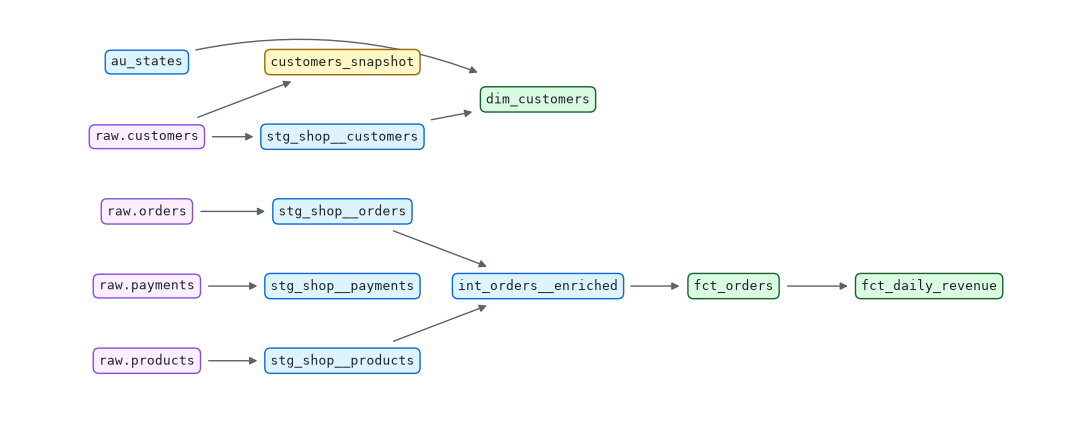

In [15]:
result = dbt("docs", "generate", quiet=True)
assert result.success

edges = artifacts.lineage_edges()
assert ("int_orders__enriched", "fct_orders") in edges
assert ("fct_orders", "fct_daily_revenue") in edges
print(f"✓ {len(edges)} edges in the manifest · every arrow below is one of them")
artifacts.lineage_figure()

## What dbt does not do

Worth stating plainly, because the rest of this series lives in the gaps:

- **No ingestion.** Something else landed `raw.*`. dbt is the T in ELT.
- **No scheduler.** `dbt build` runs when something runs it. Between runs,
  nothing is watching.
- **Tests run when *they* run.** A test that passed at 09:00 says nothing
  about the 09:30 load.
- **A model is a full statement of its table.** Every run rebuilds it from
  scratch, unless you opt out.

## What this notebook showed

| you typed | you got |
|---|---|
| `dbt run --select …` | models materialised in dependency order, DDL chosen by config |
| `dbt test --select …` | 26 expectations on that path, executed against the live warehouse |
| `dbt build` | the whole project (models, tests, seed, snapshot) in one command |
| `dbt docs generate` | lineage drawn from the code, not maintained beside it |

We now have a working, tested pipeline. Every run rebuilds every table *unless you opt out*, and one
model does. The run log above reads `incremental model
marts.fct_orders`, not `table model` like its neighbour. It is the only
model in this project carrying its own overriding `config` block.

*Next: [when rebuilds stop scaling →](02-incremental-models.ipynb)*